In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

C:\Users\potab\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df = pd.read_csv('energy consumption.csv')
df.head()

,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption,Anomaly_Label
0,01-01-2024 00:00,0.457786,0.469524,0.396368,0.445441,0.692057,0
1,01-01-2024 00:30,0.351956,0.465545,0.451184,0.458729,0.539874,0
2,01-01-2024 01:00,0.482948,0.285415,0.408289,0.470360,0.614724,0
3,01-01-2024 01:30,0.628838,0.482095,0.512308,0.576241,0.757044,0
4,01-01-2024 02:00,0.335974,0.624741,0.672021,0.373004,0.673981,0


In [3]:
df['Anomaly_Label'].value_counts()

Anomaly_Label
0    4750
1     250
Name: count, dtype: int64

In [4]:
df['Timestamp'] = pd.to_datetime(
    df['Timestamp'],
    format = '%d-%m-%Y %H:%M'
)

df = df.sort_values('Timestamp').reset_index(drop = True)

In [5]:
X = df.drop(['Anomaly_Label', 'Timestamp'], axis = 1)
y = df['Anomaly_Label']

In [6]:
split = int(len(X) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (4000, 5)
Testing data shape: (1000, 5)


In [7]:
X_train_normal = X_train[y_train == 0]

In [10]:
scaler = StandardScaler()

scaler.fit(X_train[y_train == 0])

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

C:\Users\potab\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [11]:
window_size = 10

def create_windows(X, y, window_size):

    X_windows = []
    y_windows = []

    for i in range(len(X) - window_size + 1):
        X_windows.append(X[i : i + window_size])

        y_windows.append(
            np.max(y.iloc[i : i + window_size])
        )

    return np.array(X_windows), np.array(y_windows)        

X_train_windows, y_train_windows = create_windows(
    X_train_scaled, y_train, window_size
)

X_test_windows, y_test_windows = create_windows(
    X_test_scaled, y_test, window_size
)

X_train_normal = X_train_windows[y_train_windows == 0]

print("Training windows shape:", X_train_normal.shape)
print("Testing windows shape:", X_test_windows.shape)

Training windows shape: (2828, 10, 5)
Testing windows shape: (991, 10, 5)


In [13]:
timesteps = X_train_normal.shape[1]
input_dim = X_train_normal.shape[2]

autoencoder = keras.Sequential([
    keras.Input(shape = (timesteps, input_dim)),
    layers.LSTM(32, activation = 'relu', return_sequences = True),
    layers.LSTM(16, activation = 'relu', return_sequences = False),
    layers.RepeatVector(timesteps),
    layers.LSTM(16, activation = 'relu', return_sequences = True),
    layers.LSTM(32, activation = 'relu', return_sequences = True),
    layers.TimeDistributed(layers.Dense(input_dim))   
])

In [15]:
autoencoder.compile(
    optimizer = 'adam',
    loss = 'mse',
    metrics = ['mae']
)

In [16]:
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs = 11,
    batch_size = 64,
    validation_split = 0.2
)

Epoch 1/11
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 108ms/step - loss: 0.9444 - mae: 0.7768 - val_loss: 0.9322 - val_mae: 0.7686
Epoch 2/11
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 0.8982 - mae: 0.7510 - val_loss: 0.8972 - val_mae: 0.7484
Epoch 3/11
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.8630 - mae: 0.7320 - val_loss: 0.8701 - val_mae: 0.7333
Epoch 4/11
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - loss: 0.8333 - mae: 0.7168 - val_loss: 0.8437 - val_mae: 0.7212
Epoch 5/11
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.8038 - mae: 0.7008 - val_loss: 0.8218 - val_mae: 0.7089
Epoch 6/11
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.7862 - mae: 0.6902 - val_loss: 0.8064 - val_mae: 0.6998
Epoch 7/11
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 0.7690 - mae: 0.6793 - val_loss: 0.7858 - val_mae: 0.6880
Epoch 8/11
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.7548 - mae: 0.6716 - val_loss: 0.7799 - val_mae: 0.6841
Epoch 9/11
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.7

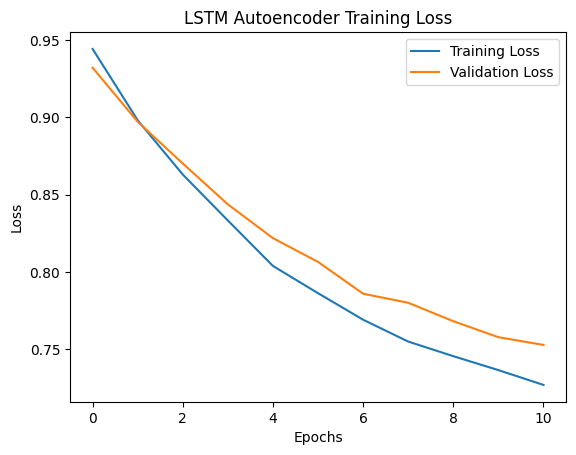

In [17]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [19]:
X_train_pred = autoencoder.predict(X_train_normal)
X_test_pred = autoencoder.predict(X_test_windows)

train_error = np.mean(np.square(X_train_normal - X_train_pred), axis = (1, 2))
test_error = np.mean(np.square(X_test_windows - X_test_pred), axis = (1, 2))

threshold = np.percentile(train_error, 95)
print("Reconstruction Error Threshold:", threshold)

89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step 
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
Reconstruction Error Threshold: 0.999383845376588


In [20]:
y_pred = (test_error > threshold).astype(int)

print("Predicted classes:")
print(y_pred[:20])

Predicted classes:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


              precision    recall  f1-score   support

           0       0.00      0.00      0.00       698
           1       0.30      1.00      0.46       293

    accuracy                           0.30       991
   macro avg       0.15      0.50      0.23       991
weighted avg       0.09      0.30      0.13       991



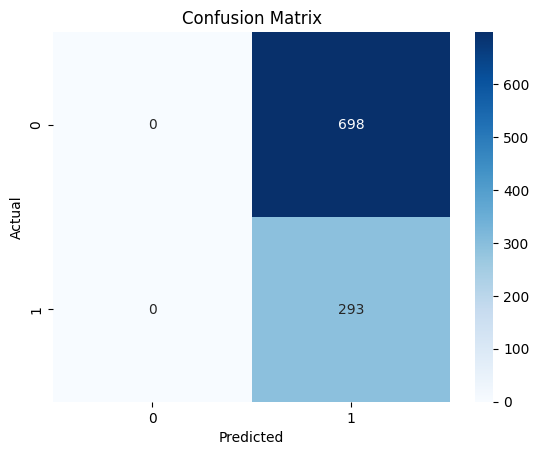

In [22]:
print(classification_report(y_test_windows, y_pred, zero_division = 0))

cm = confusion_matrix(y_test_windows, y_pred)
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()